<a href="https://colab.research.google.com/github/BintangPancahaya/PCVK26_06_BintangPP/blob/main/Week10_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 – Dasar-Dasar Deteksi Obyek
**Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi, Polinema**

Nama : Bintang Pancahaya Prasetyo<br>
Kelas : TI-3F<br>
NIM : 244107020115

# D. Tugas Praktikum
## D1. Praktikum Deteksi Obyek Dasar

In [ ]:
# Colab saat ini memakai OpenCV 5.x yang tidak lagi menyertakan cv.CascadeClassifier (Haar Cascade untuk face detection).
# Karena itu dipakai OpenCV 4.x versi contrib (sudah lengkap: CascadeClassifier + SIFT).
# Cell ini harus dijalankan sebelum cv2 di-import.
import importlib.metadata as md

def versi(paket):
    try:
        return md.version(paket)
    except md.PackageNotFoundError:
        return ''

if versi('opencv-python').startswith('5') or versi('opencv-python-headless').startswith('5') or not versi('opencv-contrib-python').startswith('4'):
    !pip uninstall -y -q opencv-python opencv-python-headless
    !pip install -q --force-reinstall --no-deps opencv-contrib-python==4.14.0.94

print('opencv-contrib-python', versi('opencv-contrib-python'))

opencv-contrib-python 4.14.0.94


In [ ]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
#akses drive
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# folder gambar praktikum Week 10 (salinan dari folder gambar modul)
PATH = '/content/drive/MyDrive/PCVK/Week10/'

import os
for f in sorted(os.listdir(PATH)):
    img = cv.imread(PATH + f)
    print(f'{f:22s}', None if img is None else img.shape)

bahrain-template.jpg   (73, 88, 3)
bahrain.jpg            (586, 596, 3)
car-park.jpg           (619, 1100, 3)
cat-and-rabbit.jpg     (491, 640, 3)
cat2_templatejpg.jpg   (449, 356, 3)
cats_and_bunnies.jpg   (829, 1024, 3)
chess-board.jpg        (800, 1000, 3)
couple.tiff            (256, 256, 3)
female.tiff            (256, 256, 3)
kids.jpeg              (1600, 720, 3)
kitten01.jpg           (627, 670, 3)
ktm.jpg                (1288, 2112, 3)
ktm2.jpg               (1516, 2413, 3)
laptop.jpg             (2560, 3840, 3)
lena.jpg               (512, 512, 3)
male.tiff              (1024, 1024, 3)
people.jpg             (1275, 1920, 3)
prabowo.jpg            (252, 200, 3)
sudoku.jpg             (375, 500, 3)


### Langkah 2 – Template Matching (6 metode OpenCV)
Menggunakan library OpenCV:

**cv.matchTemplate()**, dengan parameter:
- **image**: citra input
- **templ**: template yang dicari, ukurannya tidak boleh lebih besar dari citra input
- **method**: metode dari template matching

Jenis metode template matching di OpenCV:
1. TM_SQDIFF
2. TM_SQDIFF_NORMED
3. TM_CCORR
4. TM_CCORR_NORMED
5. TM_CCOEFF
6. TM_CCOEFF_NORMED

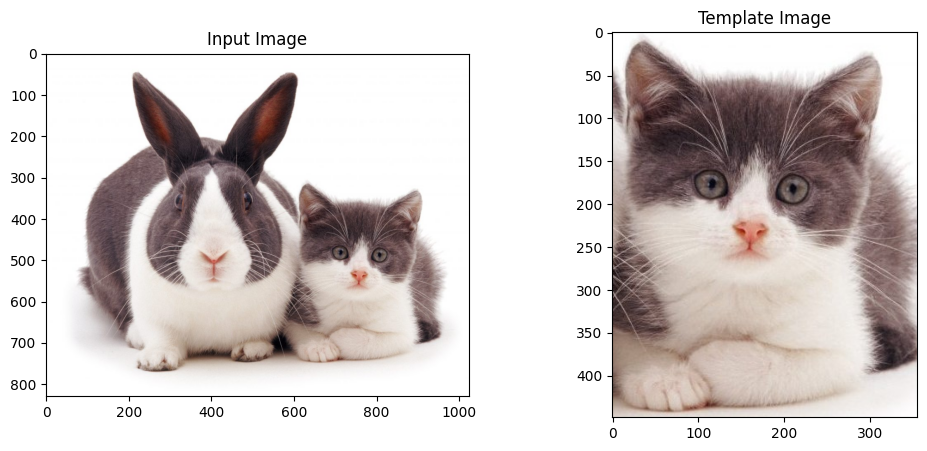

In [ ]:
full = cv.imread(PATH + 'cats_and_bunnies.jpg')
full = cv.cvtColor(full, cv.COLOR_BGR2RGB)

face = cv.imread(PATH + 'cat2_templatejpg.jpg')
face = cv.cvtColor(face, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(full), plt.title('Input Image')
plt.subplot(122), plt.imshow(face), plt.title('Template Image')
plt.show()

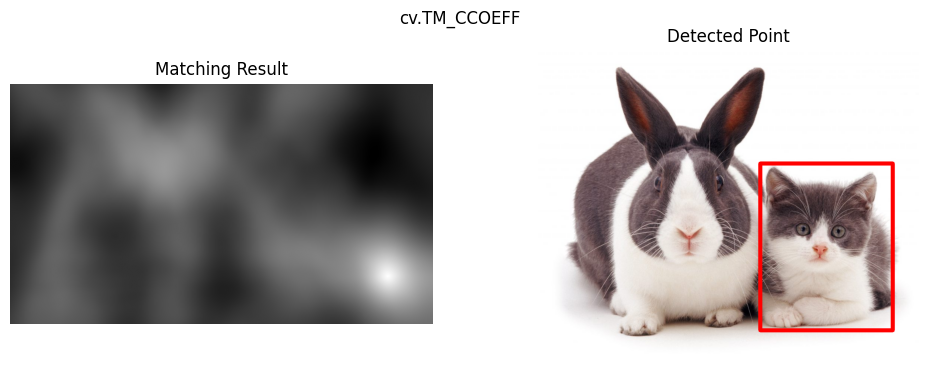

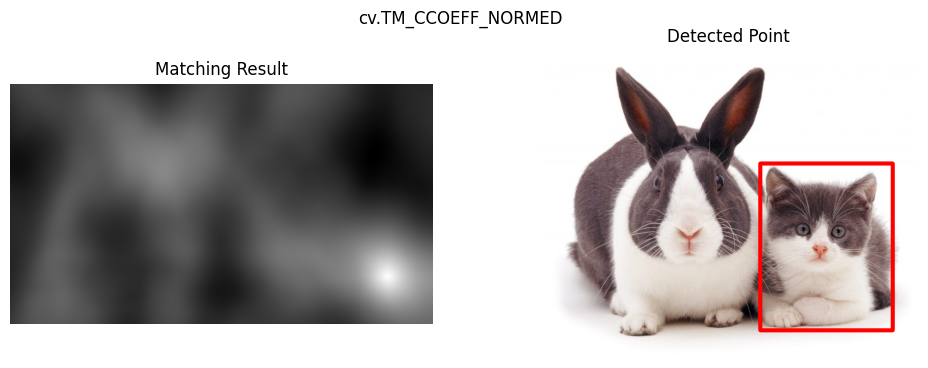

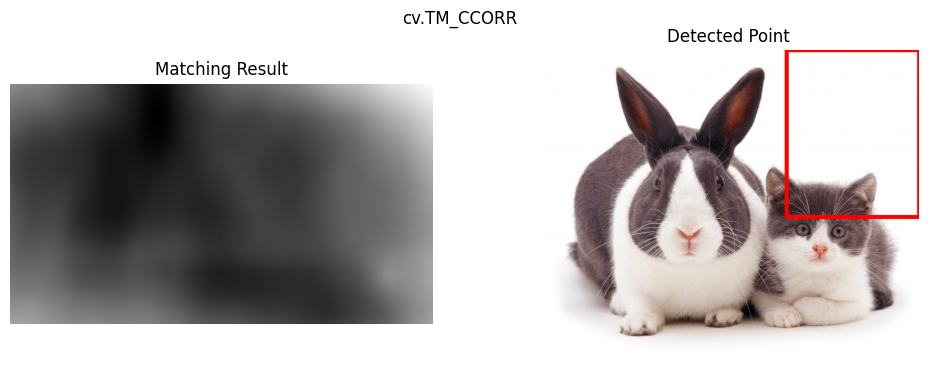

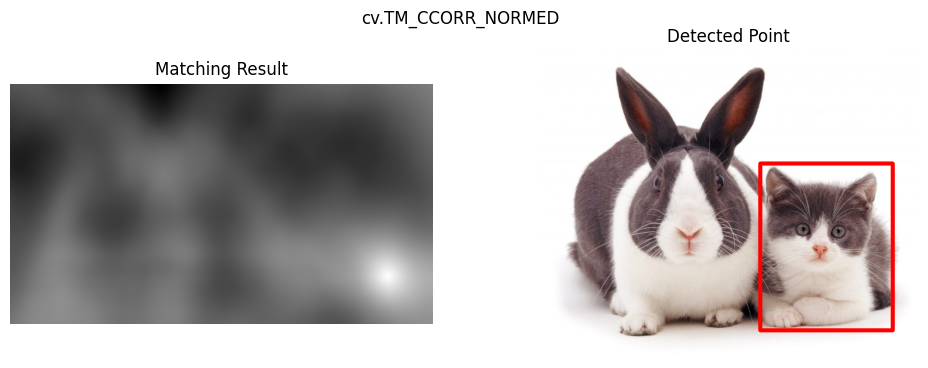

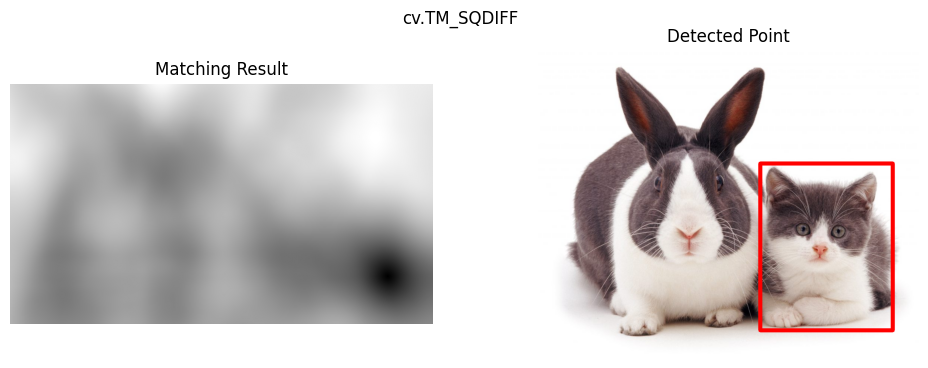

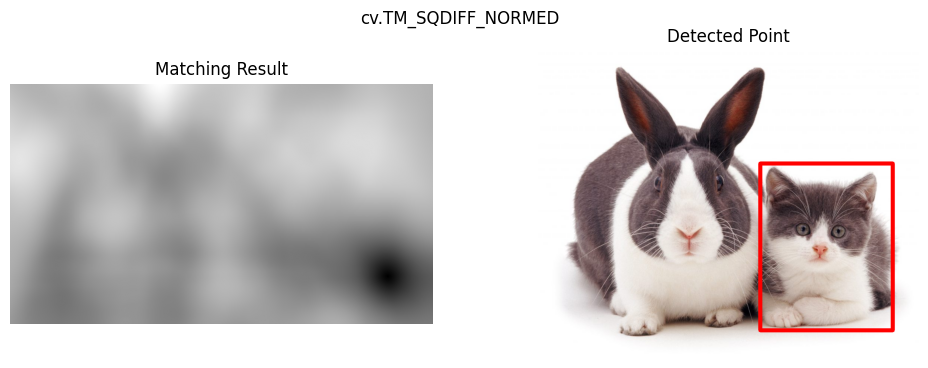

In [ ]:
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for m in methods:
    full_copy = full.copy()
    method = eval(m)

    # template matching
    res = cv.matchTemplate(full_copy, face, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # untuk SQDIFF, kecocokan terbaik = nilai minimum; metode lain = nilai maksimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    height, width, channels = face.shape
    bottom_right = (top_left[0] + width, top_left[1] + height)
    cv.rectangle(full_copy, top_left, bottom_right, (255, 0, 0), 10)

    plt.figure(figsize=(12, 4))
    plt.subplot(121), plt.imshow(res, cmap='gray'), plt.title('Matching Result'), plt.axis('off')
    plt.subplot(122), plt.imshow(full_copy), plt.title('Detected Point'), plt.axis('off')
    plt.suptitle(m)
    plt.show()

**Analisis:** Lima metode (`TM_CCOEFF`, `TM_CCOEFF_NORMED`, `TM_CCORR_NORMED`, `TM_SQDIFF`, `TM_SQDIFF_NORMED`) berhasil menemukan kucing. Hanya `TM_CCORR` yang salah (kotak berada di pojok kanan atas), karena korelasi silang tanpa normalisasi hanya menjumlahkan perkalian intensitas, sehingga nilainya paling besar di daerah yang paling terang (latar putih), bukan di daerah yang paling mirip dengan template. Pada metode `SQDIFF`, lokasi terbaik adalah nilai **minimum** (titik gelap pada *Matching Result*), sedangkan metode lain memakai nilai **maksimum** (titik terang).

### Langkah 3 – Template Matching tanpa library OpenCV (multiple object)
Citra dibaca dengan `matplotlib` dan seluruh proses dihitung manual dengan `numpy`:
1. Citra input dan template diubah ke grayscale.
2. Template digeser ke seluruh posisi citra (`sliding_window_view`), lalu di tiap posisi dihitung **Normalized Cross-Correlation (NCC)**:
   $R(x,y) = \dfrac{\sum (T' \cdot I')}{\sqrt{\sum T'^2 \cdot \sum I'^2}}$ dengan $T' = T - \bar{T}$ dan $I' = I - \bar{I}$.
3. Semua posisi dengan $R \ge$ threshold dianggap objek, lalu kotak yang saling tumpang tindih dihapus (*non-maximum suppression*) sehingga setiap objek hanya punya satu kotak.

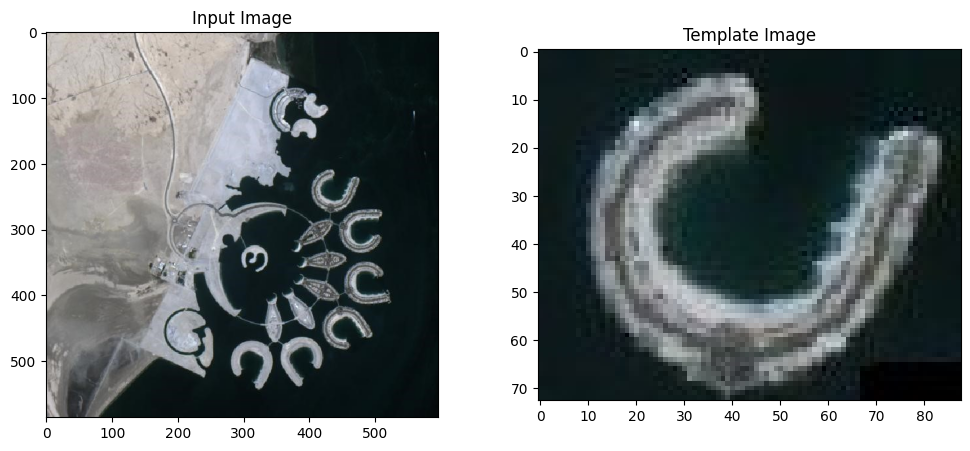

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.patches as patches

def to_gray(img):
    img = img[..., :3].astype(np.float64)
    return 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]

def template_matching_ncc(image, template):
    h, w = template.shape
    t = template - template.mean()
    windows = sliding_window_view(image, (h, w))            # (H-h+1, W-w+1, h, w)
    win_mean = windows.mean(axis=(2, 3))
    num = np.einsum('ijkl,kl->ij', windows, t)               # sum(I * T')  (= sum(I' * T') karena sum(T') = 0)
    sum_sq = np.einsum('ijkl,ijkl->ij', windows, windows)
    var_win = sum_sq - h * w * win_mean ** 2                  # sum(I'^2)
    den = np.sqrt(np.maximum(var_win, 1e-12) * (t ** 2).sum())
    return num / den

def non_max_suppression(points, scores, w, h):
    order = np.argsort(scores)[::-1]
    keep = []
    for idx in order:
        y, x = points[idx]
        if all(abs(y - ky) >= h / 2 or abs(x - kx) >= w / 2 for ky, kx in keep):
            keep.append((y, x))
    return keep

img_rgb = plt.imread(PATH + 'bahrain.jpg')
tpl_rgb = plt.imread(PATH + 'bahrain-template.jpg')
img_gray, tpl_gray = to_gray(img_rgb), to_gray(tpl_rgb)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('Input Image')
plt.subplot(122), plt.imshow(tpl_rgb), plt.title('Template Image')
plt.show()

Jumlah objek terdeteksi : 6
Skor NCC tiap objek : [0.96, 0.58, 0.52, 0.5, 0.47, 0.47]


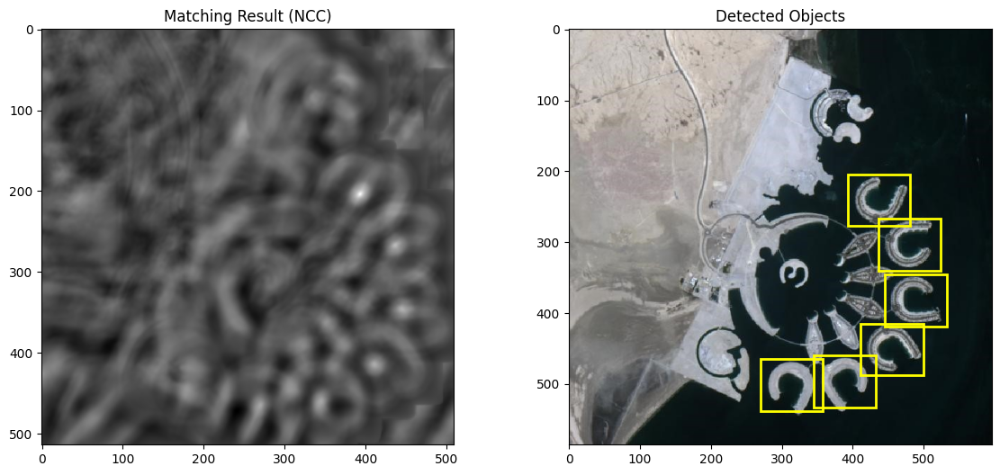

In [ ]:
R = template_matching_ncc(img_gray, tpl_gray)
h, w = tpl_gray.shape

threshold = 0.45
ys, xs = np.where(R >= threshold)
boxes = non_max_suppression(list(zip(ys, xs)), R[ys, xs], w, h)
print('Jumlah objek terdeteksi :', len(boxes))
print('Skor NCC tiap objek :', [round(float(R[y, x]), 2) for (y, x) in boxes])

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(R, cmap='gray'), ax[0].set_title('Matching Result (NCC)')
ax[1].imshow(img_rgb), ax[1].set_title('Detected Objects')
for (y, x) in boxes:
    ax[1].add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='yellow', facecolor='none'))
plt.show()

### Langkah 4 – Edge Detection (Sobel, Canny, Laplacian)

In [ ]:
car = cv.imread(PATH + 'car-park.jpg')
car_rgb = cv.cvtColor(car, cv.COLOR_BGR2RGB)
car_gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)
car_blur = cv.GaussianBlur(car_gray, (3, 3), 0)

**a. Sobel Edge Detection**

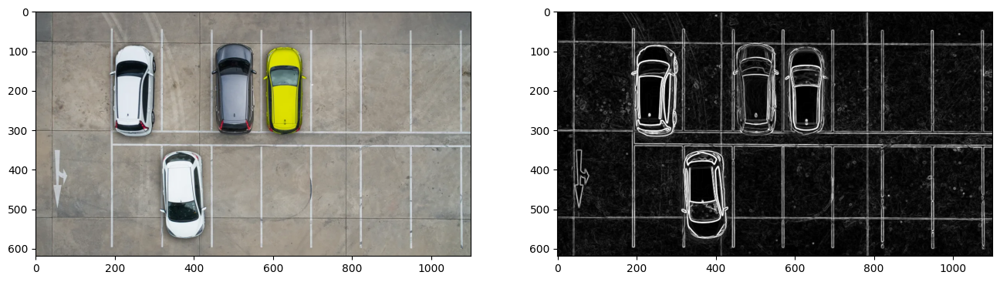

In [ ]:
sobel_x = cv.Sobel(car_blur, cv.CV_64F, 1, 0, ksize=3)   # gradien arah X
sobel_y = cv.Sobel(car_blur, cv.CV_64F, 0, 1, ksize=3)   # gradien arah Y
sobel_xy = cv.magnitude(sobel_x, sobel_y)
sobel_xy = cv.convertScaleAbs(sobel_xy)

plt.figure(figsize=(16, 6))
plt.subplot(121), plt.imshow(car_rgb)
plt.subplot(122), plt.imshow(sobel_xy, cmap='gray')
plt.show()

**b. Canny Edge Detection**

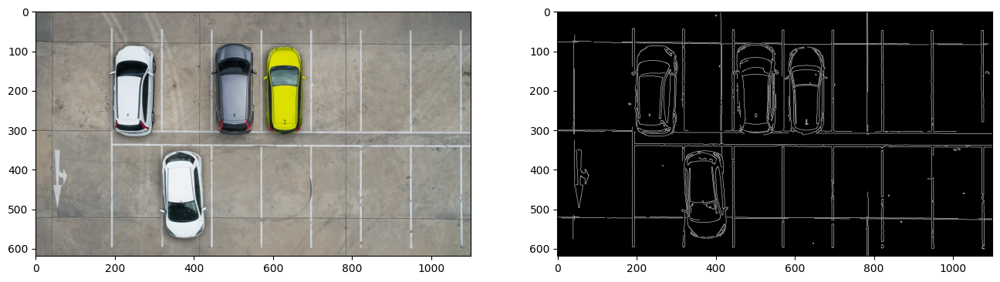

In [ ]:
canny = cv.Canny(car_blur, 100, 200)

plt.figure(figsize=(16, 6))
plt.subplot(121), plt.imshow(car_rgb)
plt.subplot(122), plt.imshow(canny, cmap='gray')
plt.show()

**c. Laplacian Edge Detection**

Laplacian sangat sensitif terhadap noise, jadi citra dihaluskan dulu dengan Gaussian filter.

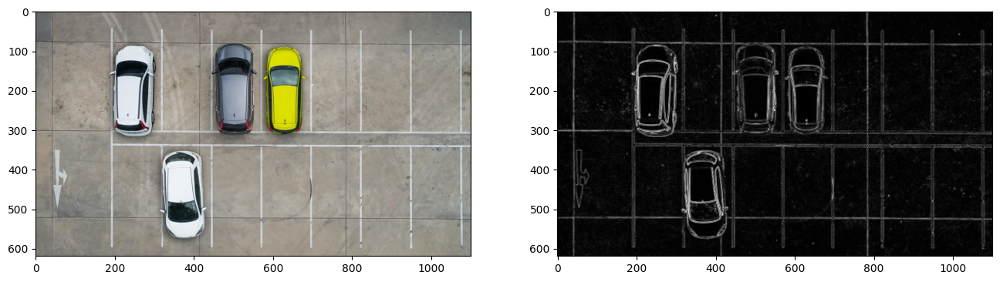

In [ ]:
laplacian = cv.Laplacian(car_blur, cv.CV_64F, ksize=3)
laplacian = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(16, 6))
plt.subplot(121), plt.imshow(car_rgb)
plt.subplot(122), plt.imshow(laplacian, cmap='gray')
plt.show()

### Langkah 5 – Corner Detection (Harris dan Shi-Tomasi)
**a. Harris Corner Detection**

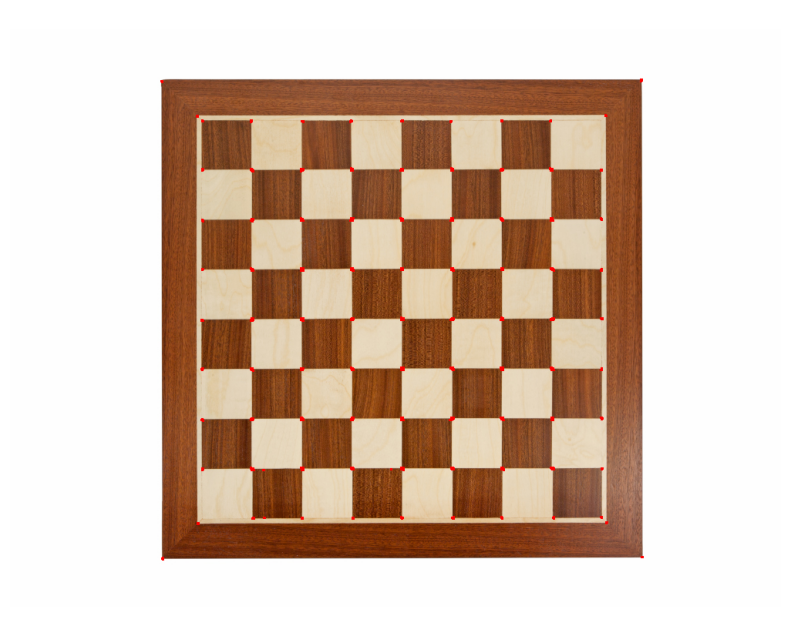

In [ ]:
chess = cv.imread(PATH + 'chess-board.jpg')
chess_rgb = cv.cvtColor(chess, cv.COLOR_BGR2RGB)
chess_gray = np.float32(cv.cvtColor(chess, cv.COLOR_BGR2GRAY))

# cornerHarris(src, blockSize, ksize, k)
dst = cv.cornerHarris(chess_gray, 2, 3, 0.04)
dst = cv.dilate(dst, None)            # memperbesar titik sudut agar terlihat

harris = chess_rgb.copy()
harris[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(10, 8))
plt.imshow(harris), plt.axis('off')
plt.show()

**b. Shi-Tomasi Corner Detection**

Jumlah sudut terdeteksi : 100


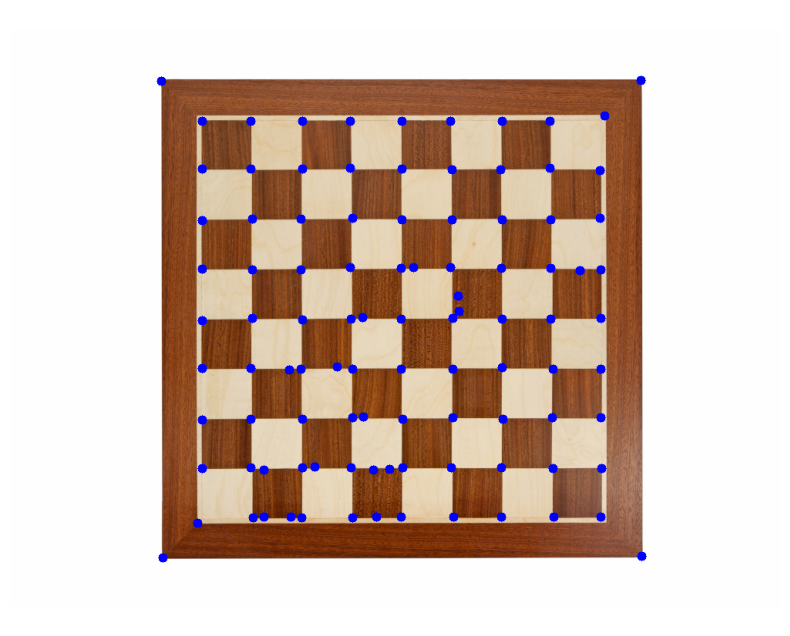

In [ ]:
gray = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

# goodFeaturesToTrack(image, maxCorners, qualityLevel, minDistance)
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.int32(corners)

shi_tomasi = chess_rgb.copy()
for c in corners:
    x, y = c.ravel()
    cv.circle(shi_tomasi, (int(x), int(y)), 6, (0, 0, 255), -1)

print('Jumlah sudut terdeteksi :', len(corners))
plt.figure(figsize=(10, 8))
plt.imshow(shi_tomasi), plt.axis('off')
plt.show()

### Langkah 6 – Grid Detection dengan Hough Transform
Tahapan sesuai ulasan teori:
1. Canny Edge Detection
2. Dilasi citra tepi
3. Erosi
4. `cv.HoughLines()`
5. Menggabungkan garis yang mirip

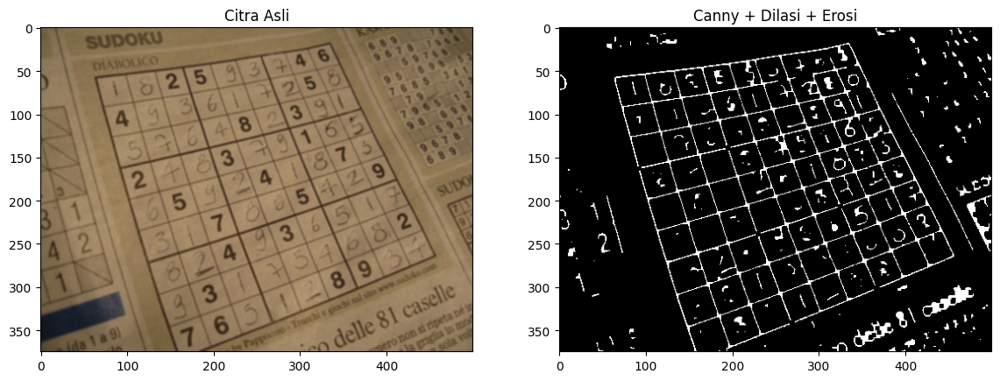

In [ ]:
sudoku = cv.imread(PATH + 'sudoku.jpg')
sudoku_rgb = cv.cvtColor(sudoku, cv.COLOR_BGR2RGB)
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

# 1. Canny
edges = cv.Canny(sudoku_gray, 90, 150, apertureSize=3)
# 2. Dilasi
kernel = np.ones((3, 3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)
# 3. Erosi
kernel = np.ones((5, 5), np.uint8)
edges = cv.erode(edges, kernel, iterations=1)

plt.figure(figsize=(14, 5))
plt.subplot(121), plt.imshow(sudoku_rgb), plt.title('Citra Asli')
plt.subplot(122), plt.imshow(edges, cmap='gray'), plt.title('Canny + Dilasi + Erosi')
plt.show()

Jumlah garis awal : 33
Jumlah garis setelah digabung : 20


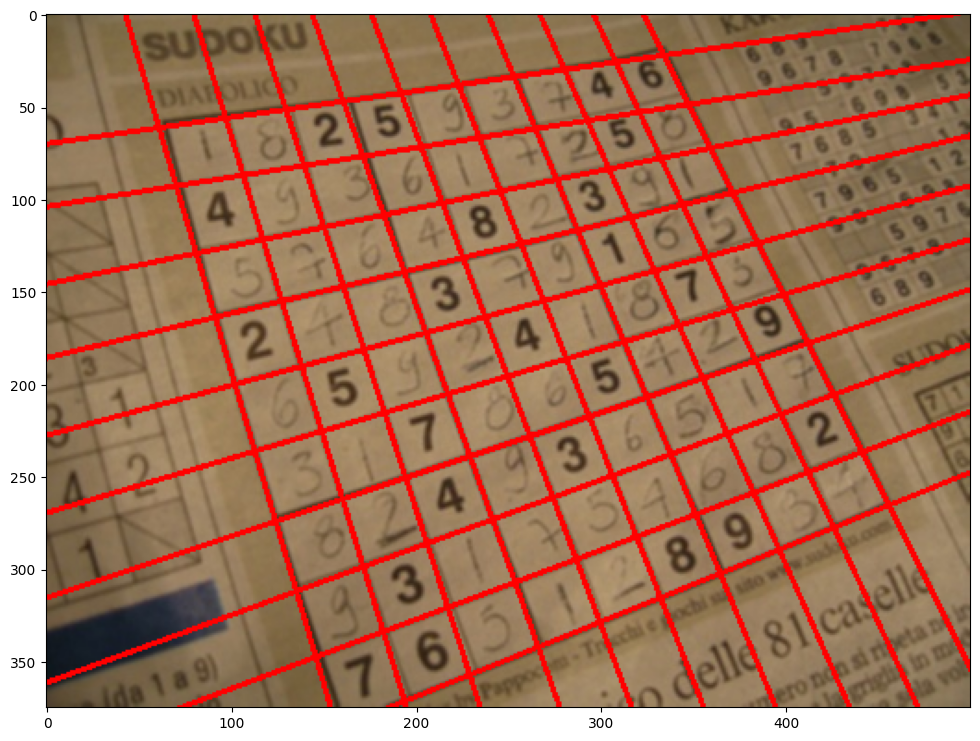

In [ ]:
# 4. Hough Transform
lines = cv.HoughLines(edges, 1, np.pi / 180, 150)
print('Jumlah garis awal :', len(lines))

# 5. Menggabungkan garis yang mirip (rho dan theta berdekatan)
def merge_similar_lines(lines, rho_thr=15, theta_thr=np.pi / 18):
    merged = []
    for rho, theta in lines[:, 0]:
        for m in merged:
            if abs(m['rho'] - rho) < rho_thr and abs(m['theta'] - theta) < theta_thr:
                m['sum'] += np.array([rho, theta]); m['n'] += 1
                m['rho'], m['theta'] = m['sum'] / m['n']
                break
        else:
            merged.append({'rho': rho, 'theta': theta, 'sum': np.array([rho, theta]), 'n': 1})
    return [(m['rho'], m['theta']) for m in merged]

merged_lines = merge_similar_lines(lines)
print('Jumlah garis setelah digabung :', len(merged_lines))

hough = sudoku_rgb.copy()
for rho, theta in merged_lines:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    pt1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
    pt2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
    cv.line(hough, pt1, pt2, (255, 0, 0), 2)

plt.figure(figsize=(12, 9))
plt.imshow(hough)
plt.show()

### Langkah 7 – Contour Detection dengan `findContours()`
Tahapan: citra diubah menjadi citra biner (Canny), kontur dicari dengan `findContours()`, lalu digambar pada citra input dengan `drawContours()`.

Jumlah kontur : 9


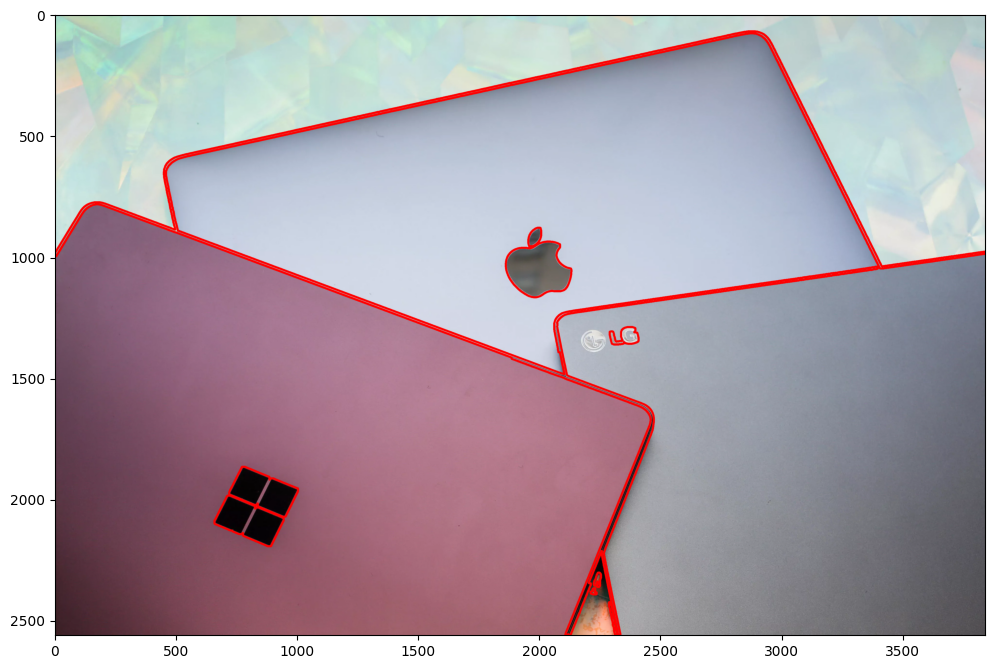

In [ ]:
laptop = cv.imread(PATH + 'laptop.jpg')
laptop_rgb = cv.cvtColor(laptop, cv.COLOR_BGR2RGB)
laptop_gray = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)

# 1. citra biner dengan Canny
blur = cv.GaussianBlur(laptop_gray, (11, 11), 0)
edged = cv.Canny(blur, 30, 120)
edged = cv.dilate(edged, np.ones((9, 9), np.uint8), iterations=1)   # menyambung tepi yang terputus

# 2. cari kontur
contours, hierarchy = cv.findContours(edged, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
print('Jumlah kontur :', len(contours))

# 3. gambar kontur pada citra input
laptop_contour = laptop_rgb.copy()
cv.drawContours(laptop_contour, contours, -1, (255, 0, 0), 8)

plt.figure(figsize=(12, 9))
plt.imshow(laptop_contour)
plt.show()

## D2. Praktikum Feature Matching dan Face Detection
### Persiapan – pretrained Haar Cascade dan citra tambahan
- Folder `facedet` dan `haarcascades` pada link gambar modul kosong, jadi file XML Haar Cascade diambil dari bawaan OpenCV (`cv.data.haarcascades`), isinya sama dengan file pretrained OpenCV.
- Citra wajah memakai citra yang tersedia di folder gambar modul: `prabowo.jpg`, `female.tiff`, `male.tiff`, `couple.tiff`, `lena.jpg`, dan `kitten01.jpg`.
- Untuk contoh **gambar bukan foto** dan **wajah bermasker** (seperti contoh pada modul), dibuat sendiri dari citra modul: sketsa pensil dari `female.tiff` (teknik *color dodge*) dan masker yang digambar di bagian bawah wajah `lena.jpg`.
- Untuk contoh **banyak wajah berukuran kecil** dan deteksi senyuman (soal 11), digunakan foto kelompok dari Wikimedia Commons (disimpan sebagai `people.jpg`, sumber dan lisensi ditampilkan pada output).

In [ ]:
HAAR = cv.data.haarcascades
print('Lokasi XML Haar Cascade :', HAAR)
print(sorted(f for f in os.listdir(HAAR) if f.endswith('.xml')))

Lokasi XML Haar Cascade : /usr/local/lib/python3.13/dist-packages/cv2/data/
['haarcascade_eye.xml', 'haarcascade_eye_tree_eyeglasses.xml', 'haarcascade_frontalcatface.xml', 'haarcascade_frontalcatface_extended.xml', 'haarcascade_frontalface_alt.xml', 'haarcascade_frontalface_alt2.xml', 'haarcascade_frontalface_alt_tree.xml', 'haarcascade_frontalface_default.xml', 'haarcascade_fullbody.xml', 'haarcascade_lefteye_2splits.xml', 'haarcascade_license_plate_rus_16stages.xml', 'haarcascade_lowerbody.xml', 'haarcascade_profileface.xml', 'haarcascade_righteye_2splits.xml', 'haarcascade_russian_plate_number.xml', 'haarcascade_smile.xml', 'haarcascade_upperbody.xml']


In [ ]:
import urllib.request, urllib.parse, json, re

def unduh(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Colab-PCVK-praktikum/1.0'})
    return urllib.request.urlopen(req, timeout=60).read()

# foto kelompok orang tersenyum dari Wikimedia Commons
FILE = '2010 Homecoming (5068212203).jpg'
api = ('https://commons.wikimedia.org/w/api.php?action=query&format=json&prop=imageinfo'
       '&iiprop=url|extmetadata&iiurlwidth=1600&titles=File:' + urllib.parse.quote(FILE))
info = list(json.loads(unduh(api))['query']['pages'].values())[0]['imageinfo'][0]

people_path = PATH + 'people.jpg'
if not os.path.exists(people_path):
    open(people_path, 'wb').write(unduh(info['thumburl']))

meta = info['extmetadata']
print('Sumber  :', info['descriptionurl'])
print('Pembuat :', re.sub('<[^>]+>', '', meta.get('Artist', {}).get('value', '-')))
print('Lisensi :', meta.get('LicenseShortName', {}).get('value', '-'))

Sumber  : https://commons.wikimedia.org/wiki/File:2010_Homecoming_(5068212203).jpg
Pembuat : Tulane Public Relations
Lisensi : CC BY 2.0


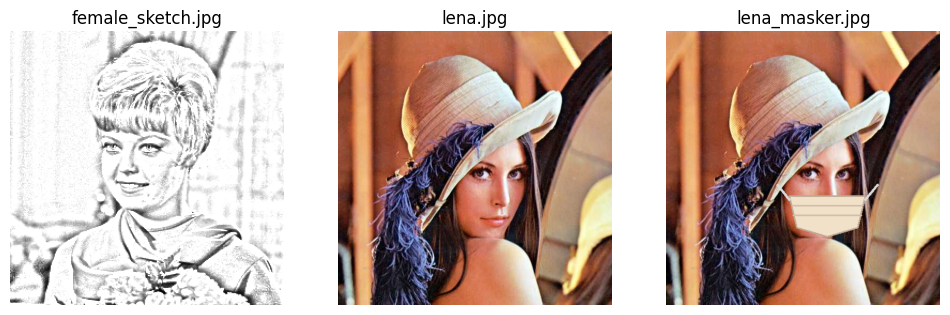

In [ ]:
cascade_wajah = cv.CascadeClassifier(HAAR + 'haarcascade_frontalface_alt.xml')

# 1. gambar bukan foto -> sketsa pensil dari female.tiff (color dodge: gray / (255 - blur(invers)))
female = cv.imread(PATH + 'female.tiff')
female_gray = cv.cvtColor(female, cv.COLOR_BGR2GRAY)
blur_inv = cv.GaussianBlur(255 - female_gray, (21, 21), 0)
sketch_gray = cv.divide(female_gray, 255 - blur_inv, scale=256)
cv.imwrite(PATH + 'female_sketch.jpg', sketch_gray)

# 2. wajah bermasker -> masker digambar pada bagian bawah wajah lena.jpg
lena = cv.imread(PATH + 'lena.jpg')
masker = lena.copy()
(x, y, w, h) = cascade_wajah.detectMultiScale(cv.cvtColor(lena, cv.COLOR_BGR2GRAY))[0]
pts = np.array([[x + int(0.10*w), y + int(0.62*h)], [x + int(0.90*w), y + int(0.62*h)],
                [x + int(0.82*w), y + int(0.95*h)], [x + w//2, y + int(1.05*h)],
                [x + int(0.18*w), y + int(0.95*h)]], np.int32)
cv.fillPoly(masker, [pts], (200, 225, 240))                                              # kain masker
cv.polylines(masker, [pts], True, (150, 170, 190), 2)
for k in [0.72, 0.82]:                                                                      # lipatan masker
    cv.line(masker, (x + int(0.14*w), y + int(k*h)), (x + int(0.86*w), y + int(k*h)), (170, 190, 210), 2)
cv.line(masker, (x + int(0.10*w), y + int(0.66*h)), (x - 5, y + int(0.50*h)), (220, 220, 220), 3)   # tali masker
cv.line(masker, (x + int(0.90*w), y + int(0.66*h)), (x + w + 5, y + int(0.50*h)), (220, 220, 220), 3)
cv.imwrite(PATH + 'lena_masker.jpg', masker)

plt.figure(figsize=(12, 4))
for i, (judul, im) in enumerate([('female_sketch.jpg', cv.cvtColor(sketch_gray, cv.COLOR_GRAY2BGR)), ('lena.jpg', lena), ('lena_masker.jpg', masker)]):
    plt.subplot(1, 3, i + 1), plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB)), plt.title(judul), plt.axis('off')
plt.show()

**Contoh face detection dari modul** (Viola-Jones, `haarcascade_frontalface_alt.xml`)

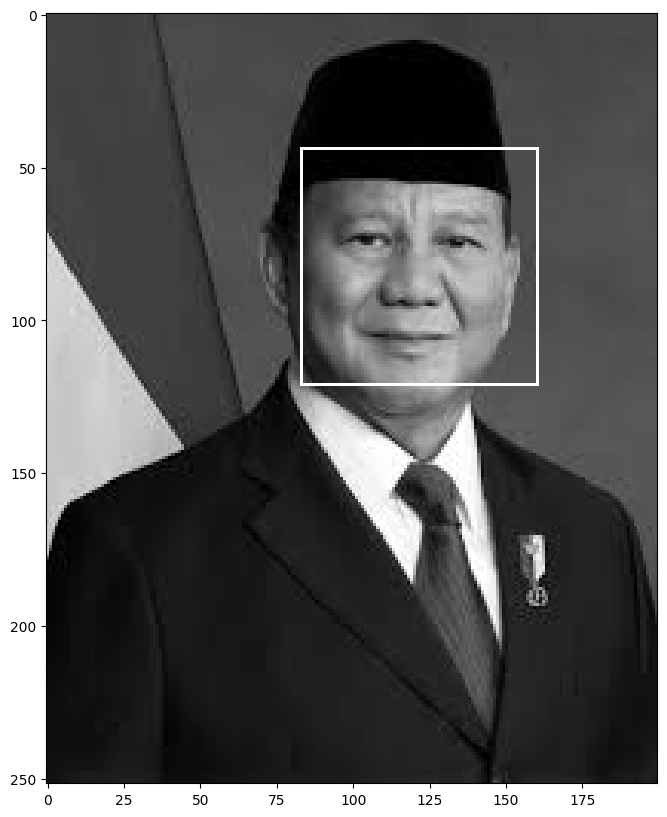

In [ ]:
cascade_wajah = cv.CascadeClassifier(HAAR + 'haarcascade_frontalface_alt.xml')   # sesuai posisi folder Haarcascade

prabowo = cv.imread(PATH + 'prabowo.jpg', 0)
roi_wajah = cascade_wajah.detectMultiScale(prabowo)
for (x, y, w, h) in roi_wajah:
    cv.rectangle(prabowo, (x, y), (x + w, y + h), (255, 255, 255), 1)
plt.figure(figsize=(10, 10))
plt.imshow(prabowo, cmap='gray')

### Langkah 8 – Face Detection untuk image lain

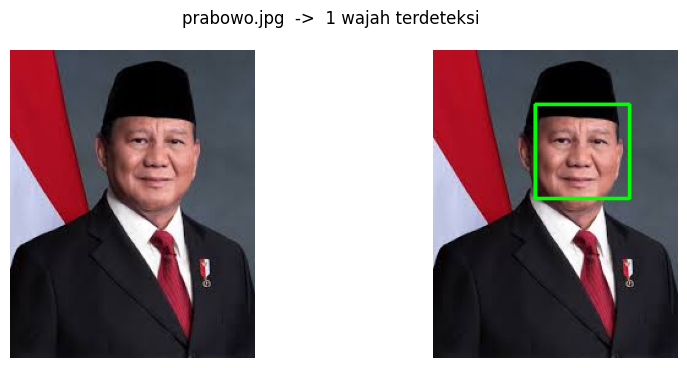

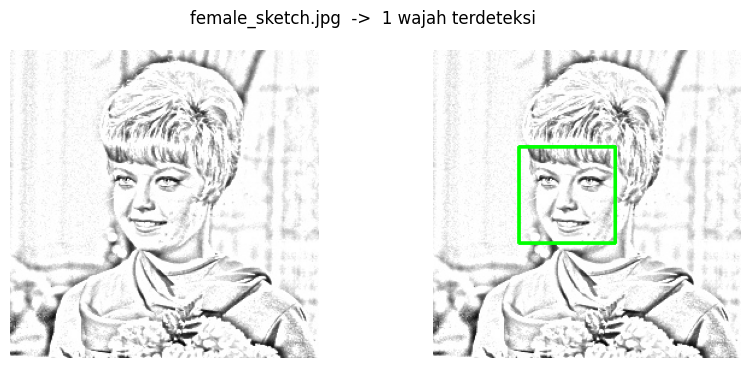

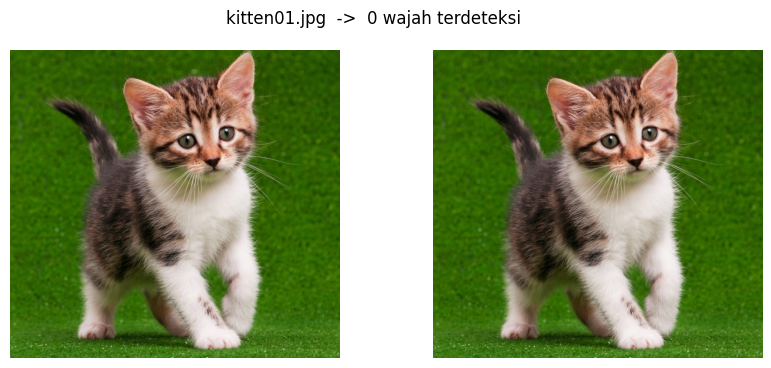

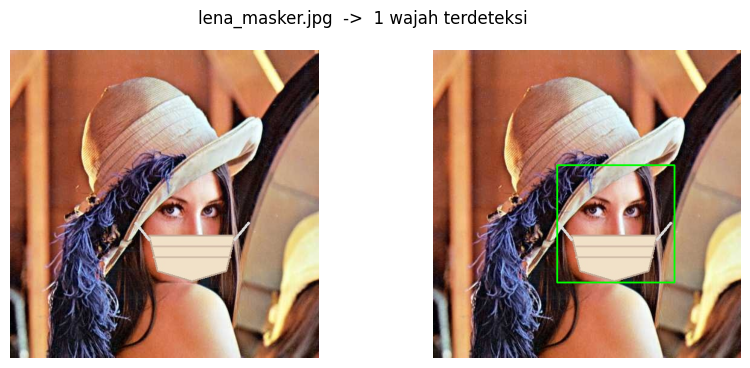

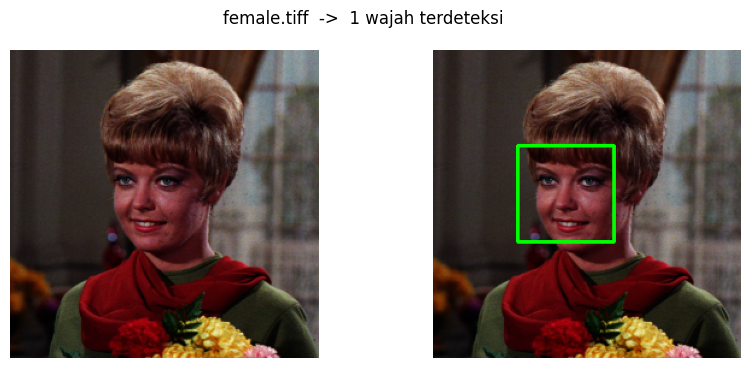

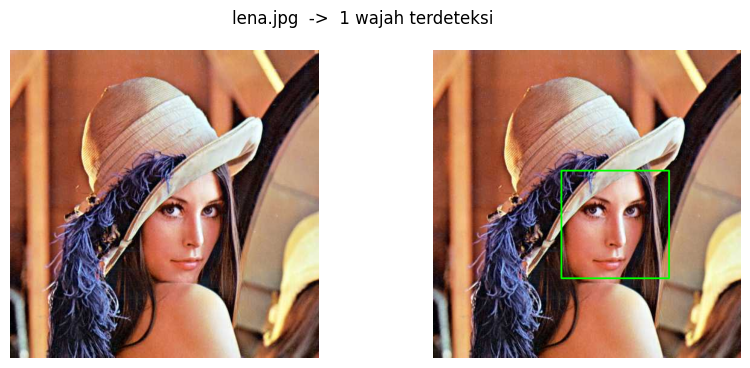

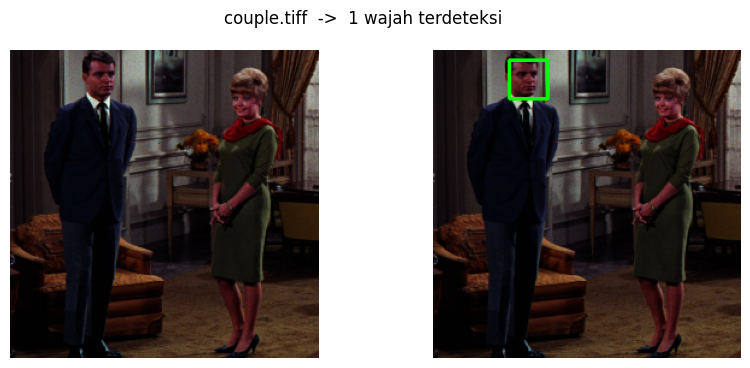

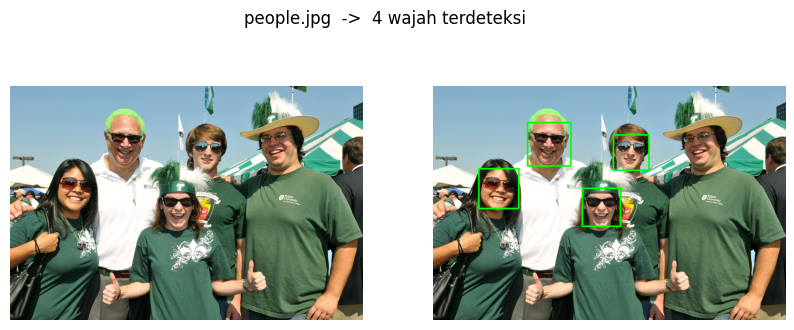

In [ ]:
# scaleFactor 1.05 (langkah skala lebih halus) dan minNeighbors 3 agar wajah kecil / bermasker / sketsa tetap terdeteksi
def deteksi_wajah(nama_file, cascade=cascade_wajah, scaleFactor=1.05, minNeighbors=3):
    img = cv.imread(PATH + nama_file)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    roi = cascade.detectMultiScale(gray, scaleFactor=scaleFactor, minNeighbors=minNeighbors)
    hasil = img.copy()
    tebal = max(2, img.shape[1] // 250)
    for (x, y, w, h) in roi:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), tebal)
    return img, hasil, len(roi)

daftar = ['prabowo.jpg', 'female_sketch.jpg', 'kitten01.jpg', 'lena_masker.jpg',
          'female.tiff', 'lena.jpg', 'couple.tiff', 'people.jpg']

for f in daftar:
    img, hasil, n = deteksi_wajah(f)
    plt.figure(figsize=(10, 4))
    plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.axis('off')
    plt.subplot(122), plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB)), plt.axis('off')
    plt.suptitle(f'{f}  ->  {n} wajah terdeteksi')
    plt.show()

**Analisis:** Secara keseluruhan face detection dengan Viola-Jones berjalan baik, termasuk pada gambar bukan foto (sketsa), wajah bermasker, dan wajah-wajah kecil pada foto kelompok. Wajah yang sedikit miring atau tertutup topi/kacamata kadang tidak terdeteksi, dan **wajah kucing (`kitten01.jpg`) tidak terdeteksi sama sekali** karena `haarcascade_frontalface_alt.xml` dilatih khusus untuk wajah manusia.

### Langkah 9 – Deteksi wajah kucing
OpenCV sudah menyediakan pretrained features untuk wajah kucing: `haarcascade_frontalcatface.xml` dan `haarcascade_frontalcatface_extended.xml`.

kitten01.jpg -> 1 wajah kucing terdeteksi


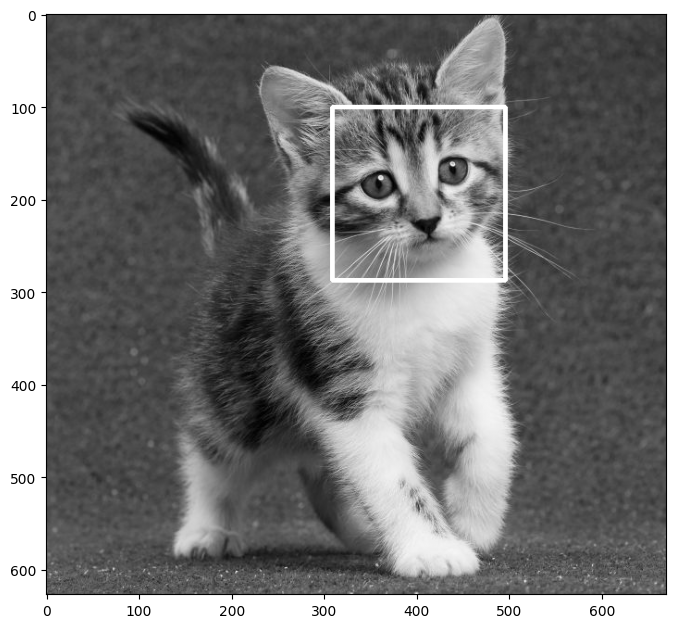

cats_and_bunnies.jpg -> 2 wajah kucing terdeteksi


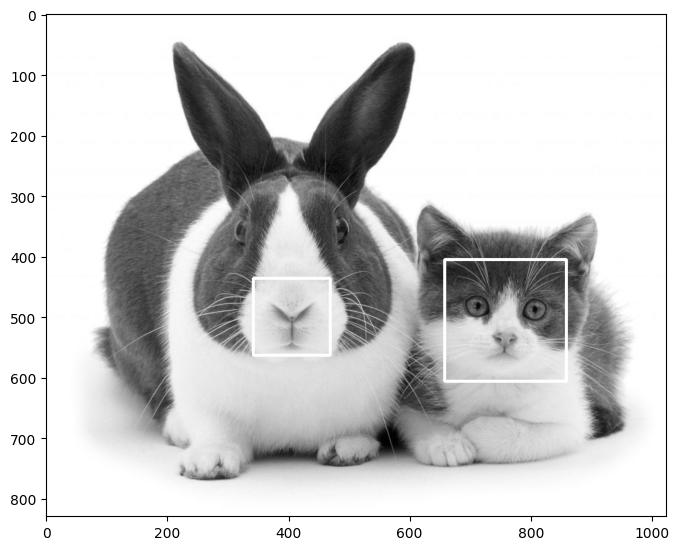

In [ ]:
cascade_kucing = cv.CascadeClassifier(HAAR + 'haarcascade_frontalcatface_extended.xml')

for f in ['kitten01.jpg', 'cats_and_bunnies.jpg']:
    kucing = cv.imread(PATH + f, 0)
    roi_kucing = cascade_kucing.detectMultiScale(kucing, scaleFactor=1.05, minNeighbors=5)
    for (x, y, w, h) in roi_kucing:
        cv.rectangle(kucing, (x, y), (x + w, y + h), (255, 255, 255), 3)
    print(f, '->', len(roi_kucing), 'wajah kucing terdeteksi')
    plt.figure(figsize=(8, 8))
    plt.imshow(kucing, cmap='gray')
    plt.show()

### Langkah 10 – Eyes detection pada wajah Pak Prabowo
Mata dicari di dalam area wajah (ROI) menggunakan `haarcascade_eye.xml`.

Jumlah mata terdeteksi : 2


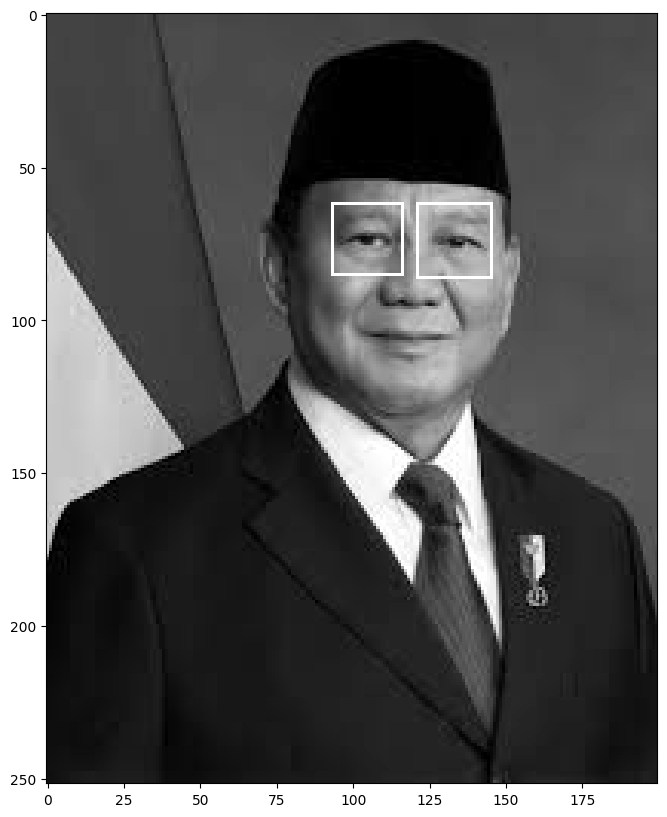

In [ ]:
cascade_mata = cv.CascadeClassifier(HAAR + 'haarcascade_eye.xml')

prabowo = cv.imread(PATH + 'prabowo.jpg', 0)
roi_wajah = cascade_wajah.detectMultiScale(prabowo)
for (x, y, w, h) in roi_wajah:
    wajah = prabowo[y:y + h, x:x + w]
    roi_mata = cascade_mata.detectMultiScale(wajah, scaleFactor=1.05, minNeighbors=5)
    for (ex, ey, ew, eh) in roi_mata:
        cv.rectangle(prabowo, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 255, 255), 1)
    print('Jumlah mata terdeteksi :', len(roi_mata))

plt.figure(figsize=(10, 10))
plt.imshow(prabowo, cmap='gray')
plt.show()

### Langkah 11 – Deteksi senyuman pada gambar people
Wajah dideteksi terlebih dahulu (kotak hijau), lalu senyuman dicari pada setengah bagian bawah wajah dengan `haarcascade_smile.xml` (kotak merah).

Wajah terdeteksi    : 4
Senyum terdeteksi   : 4


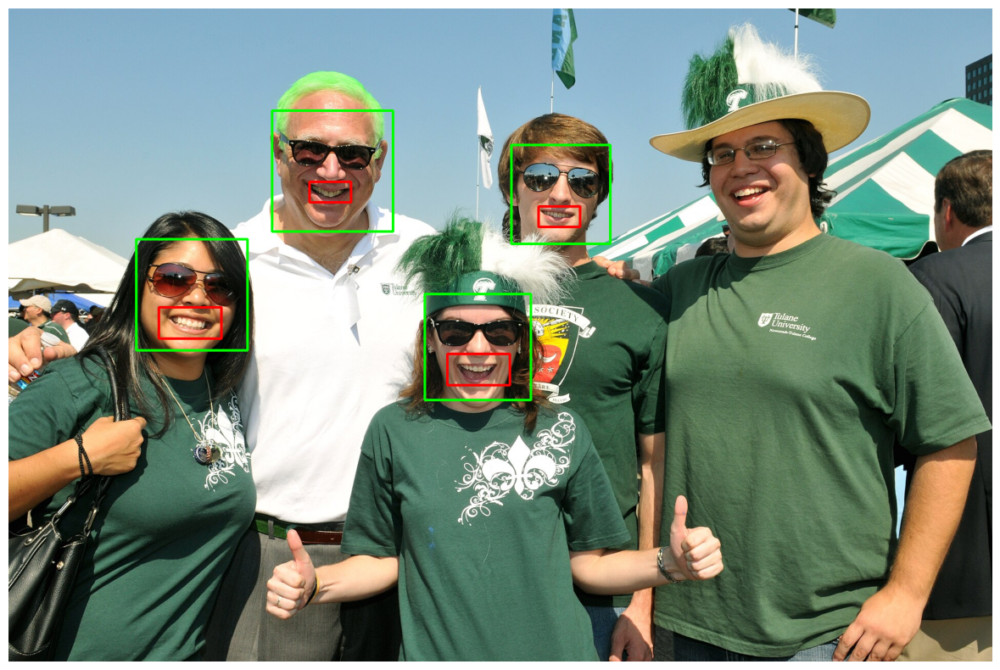

In [ ]:
cascade_senyum = cv.CascadeClassifier(HAAR + 'haarcascade_smile.xml')

people = cv.imread(PATH + 'people.jpg')
people_gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
hasil = people.copy()

roi_wajah = cascade_wajah.detectMultiScale(people_gray, scaleFactor=1.05, minNeighbors=3)
jumlah_senyum = 0
for (x, y, w, h) in roi_wajah:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 3)
    mulut = people_gray[y + h // 2:y + h, x:x + w]          # setengah bawah wajah
    roi_senyum = cascade_senyum.detectMultiScale(mulut, scaleFactor=1.5, minNeighbors=15)
    for (sx, sy, sw, sh) in roi_senyum[:1]:
        cv.rectangle(hasil, (x + sx, y + h // 2 + sy), (x + sx + sw, y + h // 2 + sy + sh), (0, 0, 255), 3)
        jumlah_senyum += 1

print('Wajah terdeteksi    :', len(roi_wajah))
print('Senyum terdeteksi   :', jumlah_senyum)
plt.figure(figsize=(15, 10))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB)), plt.axis('off')
plt.show()

**Analisis:** Dengan `haarcascade_frontalcatface_extended.xml` wajah kucing pada `kitten01.jpg` dan `cats_and_bunnies.jpg` berhasil terdeteksi. Pada `cats_and_bunnies.jpg` wajah kelinci juga ikut terdeteksi (*false positive*) karena pola terang-gelap wajah kelinci (mata, hidung, garis tengah wajah) mirip dengan fitur Haar wajah kucing.

### Langkah 12 – Face Tracking menggunakan Google Colab
Google Colab tidak bisa langsung mengakses kamera laptop dari Python, jadi kamera diakses lewat JavaScript (snippet *Camera Capture* Colab, sesuai tutorial pada modul). Frame dari kamera dikirim ke Python, wajah dideteksi dengan Haar Cascade, lalu kotak hasil deteksi dikirim balik dan ditampilkan di atas video secara *real-time*.

> Cell face tracking membutuhkan kamera laptop, jadi dijalankan manual: jalankan dua cell di bawah, izinkan akses kamera pada browser, lalu klik video untuk berhenti. (Saat *Run all*, eksekusi akan menunggu di cell ini sampai kamera diizinkan.)

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import PIL, io

def js_to_image(js_reply):
    # konversi frame JavaScript (base64) menjadi citra OpenCV (BGR)
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv.imdecode(jpg_as_np, flags=1)

def bbox_to_bytes(bbox_array):
    # konversi overlay kotak (RGBA) menjadi string base64 untuk ditampilkan di atas video
    bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_PIL.save(iobuf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(iobuf.getvalue()), 'utf-8'))

def video_stream():
    js = Javascript('''
    var video; var div = null; var stream; var captureCanvas; var imgElement; var labelElement;
    var pendingResolve = null; var shutdown = false;
    function removeDom() {
       stream.getVideoTracks()[0].stop(); video.remove(); div.remove();
       video = null; div = null; stream = null; imgElement = null; captureCanvas = null; labelElement = null;
    }
    function onAnimationFrame() {
      if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
      if (pendingResolve) {
        var result = '';
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var lp = pendingResolve; pendingResolve = null; lp(result);
      }
    }
    async function createDom() {
      if (div !== null) { return stream; }
      div = document.createElement('div');
      div.style.border = '2px solid black'; div.style.padding = '3px'; div.style.width = '100%'; div.style.maxWidth = '600px';
      document.body.appendChild(div);
      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span'); labelElement.innerText = 'No data'; labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement); div.appendChild(modelOut);
      video = document.createElement('video');
      video.style.display = 'block'; video.width = div.clientWidth - 6; video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: { facingMode: "environment"}});
      div.appendChild(video);
      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute'; imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);
      const instruction = document.createElement('div');
      instruction.innerHTML = '<span style="color: red; font-weight: bold;">Klik video untuk berhenti</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };
      video.srcObject = stream;
      await video.play();
      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) { removeDom(); shutdown = false; return ''; }
      var preCreate = Date.now();
      stream = await createDom();
      var preShow = Date.now();
      if (label != "") { labelElement.innerHTML = label; }
      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px"; imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px"; imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }
      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
      shutdown = false;
      return {'create': preShow - preCreate, 'show': preCapture - preShow, 'capture': Date.now() - preCapture, 'img': result};
    }
    ''')
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

In [ ]:
# face tracking real-time dari webcam
video_stream()
label_html = 'Mendeteksi wajah...'
bbox = ''
jumlah_frame = 0
while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break
    img = js_to_image(js_reply['img'])
    bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)        # overlay transparan
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    faces = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
    for (x, y, w, h) in faces:
        bbox_array = cv.rectangle(bbox_array, (x, y), (x + w, y + h), (0, 255, 0), 2)
    bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255
    bbox = bbox_to_bytes(bbox_array)
    label_html = f'{len(faces)} wajah terdeteksi'
    jumlah_frame += 1
print('Face tracking selesai, frame yang diproses :', jumlah_frame)

### Langkah 13 – Blurring pada wajah yang terdeteksi
Area wajah hasil deteksi diambil (ROI), di-*blur* dengan `cv.medianBlur`, lalu ditempel kembali ke citra.

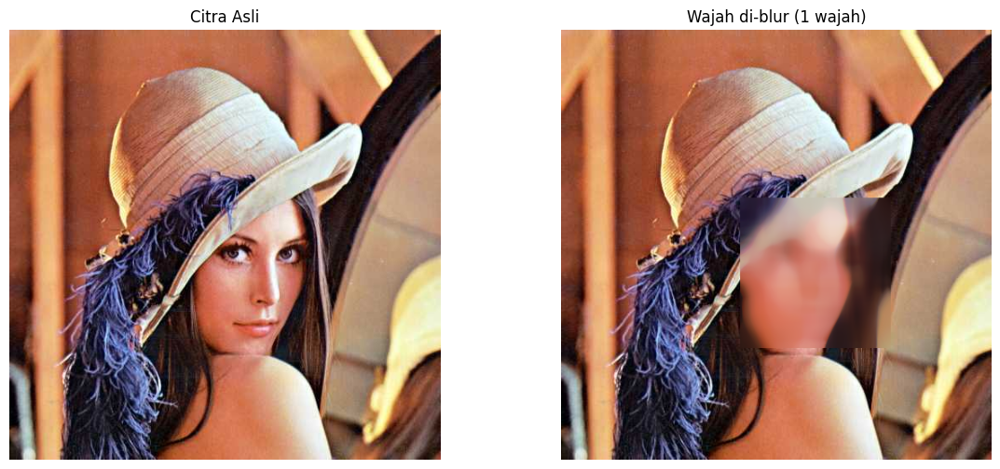

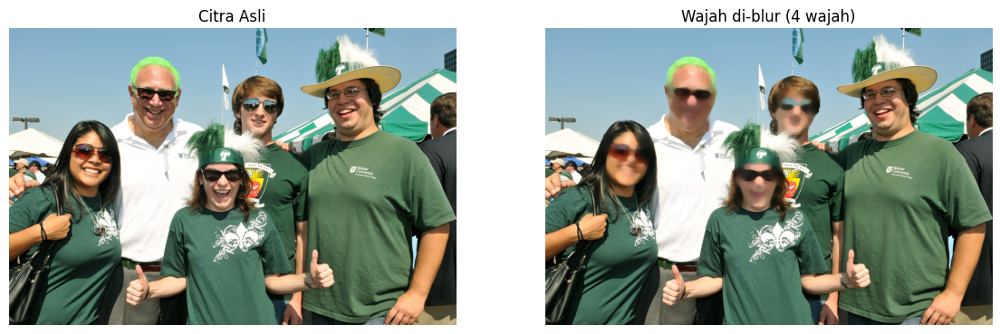

In [ ]:
def blur_wajah(nama_file, ksize=31):
    img = cv.imread(PATH + nama_file)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    hasil = img.copy()
    roi = cascade_wajah.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3)
    for (x, y, w, h) in roi:
        hasil[y:y + h, x:x + w] = cv.medianBlur(hasil[y:y + h, x:x + w], ksize)
    return img, hasil, len(roi)

for f, k in [('lena.jpg', 41), ('people.jpg', 31)]:
    img, hasil, n = blur_wajah(f, k)
    plt.figure(figsize=(14, 6))
    plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Citra Asli'), plt.axis('off')
    plt.subplot(122), plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB)), plt.title(f'Wajah di-blur ({n} wajah)'), plt.axis('off')
    plt.show()

### Langkah 14 – Mengolah gambar KTM
**a. KTM milik sendiri**

Ukuran KTM : (1288, 2112, 3)


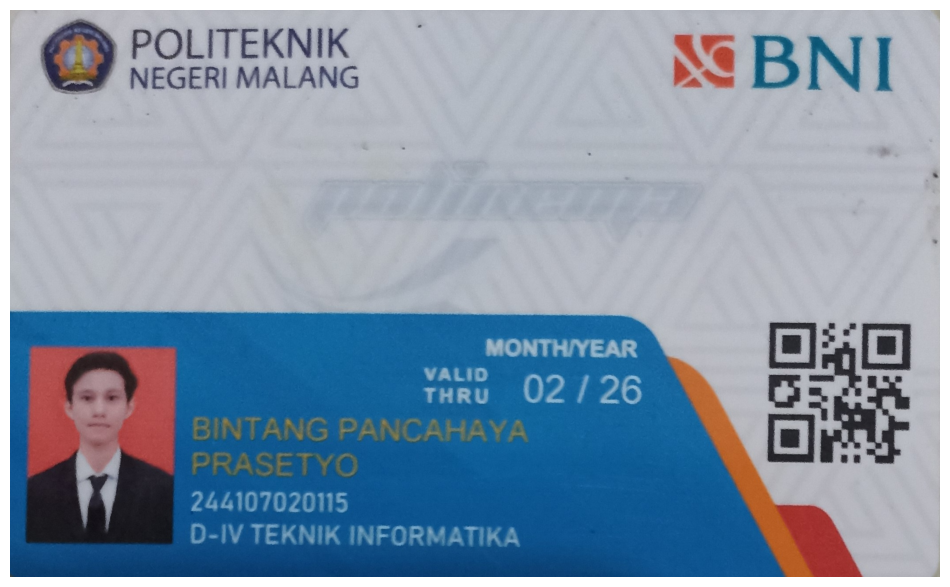

In [ ]:
ktm = cv.imread(PATH + 'ktm.jpg')
ktm_rgb = cv.cvtColor(ktm, cv.COLOR_BGR2RGB)
print('Ukuran KTM :', ktm.shape)

plt.figure(figsize=(12, 8))
plt.imshow(ktm_rgb), plt.axis('off')
plt.show()

**b. Menampilkan Foto KTM**

Foto pada KTM memiliki latar belakang merah, sehingga area foto dicari dengan *color segmentation* di ruang warna HSV (warna merah), lalu kontur terbesar diambil sebagai area foto. Sebagai verifikasi, wajah di dalam foto juga dideteksi dengan Haar Cascade.

Posisi foto pada KTM (x, y, w, h): (42, 768, 333, 295) | wajah terdeteksi: 1


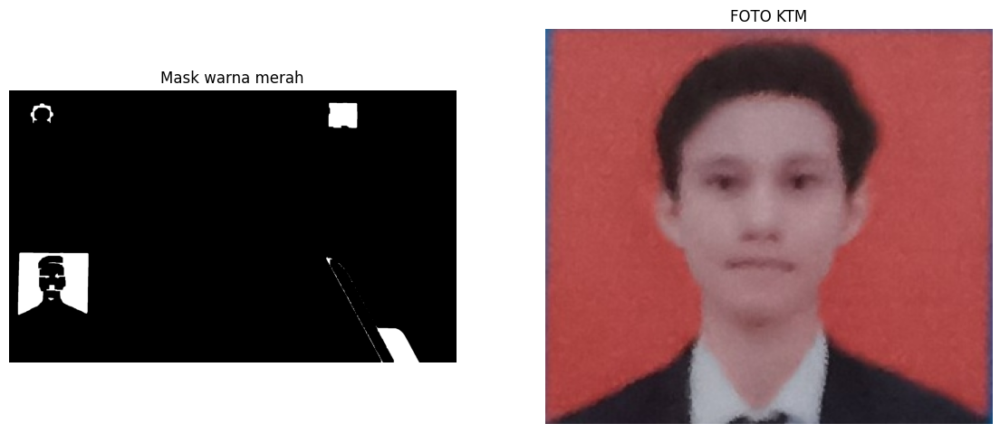

In [ ]:
hsv = cv.cvtColor(ktm, cv.COLOR_BGR2HSV)

# warna merah berada di dua ujung rentang Hue (0-10 dan 170-180)
mask_merah = cv.inRange(hsv, (0, 90, 70), (10, 255, 255)) | cv.inRange(hsv, (170, 90, 70), (180, 255, 255))
mask_merah = cv.morphologyEx(mask_merah, cv.MORPH_CLOSE, np.ones((25, 25), np.uint8))

contours, _ = cv.findContours(mask_merah, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
x, y, w, h = cv.boundingRect(max(contours, key=cv.contourArea))
foto_ktm = ktm_rgb[y:y + h, x:x + w]

# verifikasi: deteksi wajah di dalam foto KTM
wajah = cascade_wajah.detectMultiScale(cv.cvtColor(foto_ktm, cv.COLOR_RGB2GRAY), scaleFactor=1.05, minNeighbors=5)
print('Posisi foto pada KTM (x, y, w, h):', (x, y, w, h), '| wajah terdeteksi:', len(wajah))

plt.figure(figsize=(14, 6))
plt.subplot(121), plt.imshow(mask_merah, cmap='gray'), plt.title('Mask warna merah'), plt.axis('off')
plt.subplot(122), plt.imshow(foto_ktm), plt.title('FOTO KTM'), plt.axis('off')
plt.show()

**c. Deteksi Obyek KTM dengan konsep Feature Matching**

Citra uji berisi KTM bersama barang lain disusun dari citra yang tersedia: foto KTM lain (`ktm2.jpg`, diambil dengan pencahayaan dan posisi berbeda) diletakkan miring di atas meja berisi laptop (`laptop.jpg`), foto kucing, dan kertas sudoku. KTM referensi (`ktm.jpg`) kemudian dicari pada citra tersebut dengan **ORB** dan **SIFT + ratio test**, lalu lokasi KTM ditentukan dengan homografi (`cv.findHomography`).

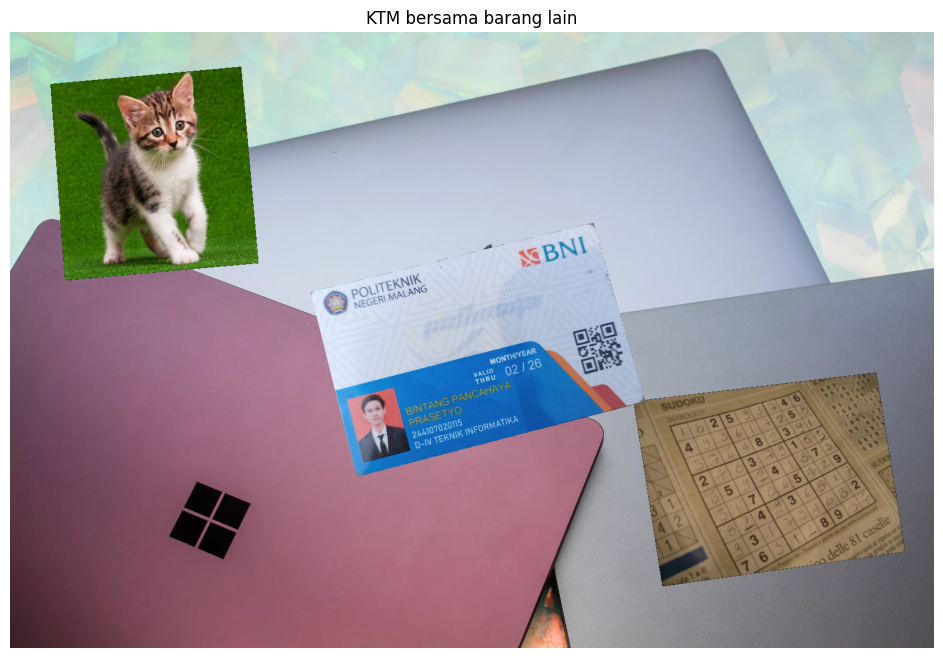

In [ ]:
def tempel(dst, src, pts_dst):
    # menempelkan citra src ke dst dengan transformasi perspektif (seolah benda diletakkan miring)
    h, w = src.shape[:2]
    M = cv.getPerspectiveTransform(np.float32([[0, 0], [w, 0], [w, h], [0, h]]), np.float32(pts_dst))
    warp = cv.warpPerspective(src, M, (dst.shape[1], dst.shape[0]))
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), M, (dst.shape[1], dst.shape[0]))
    dst[mask > 0] = warp[mask > 0]
    return dst

meja = cv.resize(cv.imread(PATH + 'laptop.jpg'), (1600, 1067))
scene = meja.copy()
scene = tempel(scene, cv.imread(PATH + 'sudoku.jpg'), [[1080, 640], [1500, 590], [1550, 900], [1130, 960]])
scene = tempel(scene, cv.imread(PATH + 'kitten01.jpg'), [[70, 90], [400, 60], [430, 400], [95, 430]])
scene = tempel(scene, cv.imread(PATH + 'ktm2.jpg'), [[520, 450], [1010, 330], [1100, 640], [600, 770]])
cv.imwrite(PATH + 'ktm_dan_barang_lain.jpg', scene)

scene_rgb = cv.cvtColor(scene, cv.COLOR_BGR2RGB)
plt.figure(figsize=(12, 8))
plt.imshow(scene_rgb), plt.title('KTM bersama barang lain'), plt.axis('off')
plt.show()

Jumlah match ORB : 647


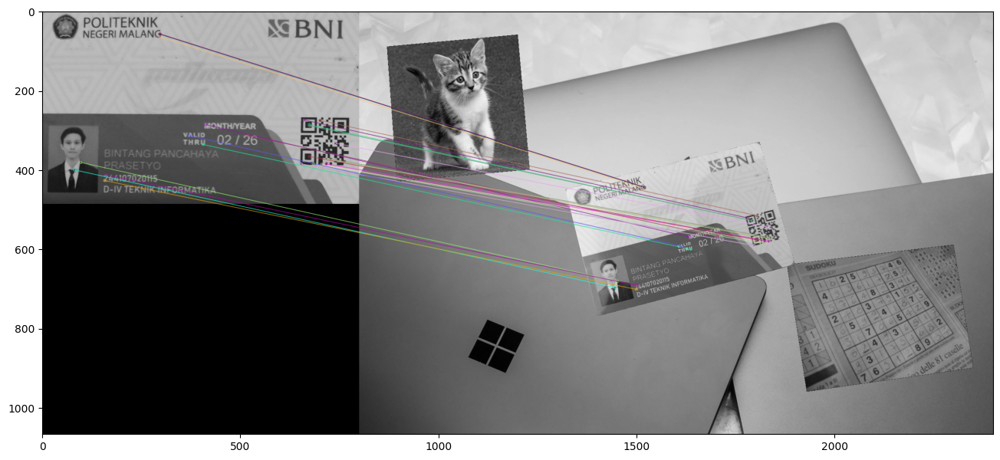

In [ ]:
def display(img, cmap='gray'):
    fig = plt.figure(figsize=(16, 10))
    ax = fig.add_subplot(111)
    ax.imshow(img, cmap=cmap)

# KTM referensi (template) diperkecil agar proses lebih cepat
ktm_ref = cv.imread(PATH + 'ktm.jpg', 0)
ktm_ref = cv.resize(ktm_ref, (800, int(800 * ktm_ref.shape[0] / ktm_ref.shape[1])))
scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

# 1. Brute-Force Matching dengan ORB Descriptor
orb = cv.ORB_create(nfeatures=2000)
kp1, des1 = orb.detectAndCompute(ktm_ref, None)
kp2, des2 = orb.detectAndCompute(scene_gray, None)
bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des1, des2), key=lambda x: x.distance)
print('Jumlah match ORB :', len(matches))

orb_match = cv.drawMatches(ktm_ref, kp1, scene_gray, kp2, matches[:25], None, flags=2)
display(orb_match)

Jumlah match SIFT : 1402 | good match (ratio test) : 392


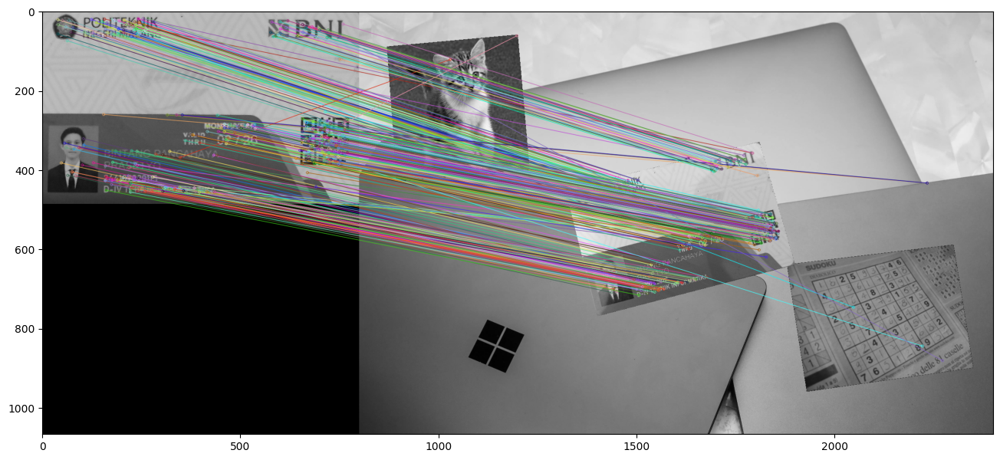

In [ ]:
# 2. Brute-Force Matching dengan SIFT Descriptor dan Ratio Test
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(ktm_ref, None)
kp2, des2 = sift.detectAndCompute(scene_gray, None)
bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good = []
# makin kecil jarak makin cocok; match1 < 75% match2 -> keypoint dianggap cocok
for match1, match2 in matches:
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])
print('Jumlah match SIFT :', len(matches), '| good match (ratio test) :', len(good))

sift_matches = cv.drawMatchesKnn(ktm_ref, kp1, scene_gray, kp2, good, None, flags=2)
display(sift_matches)

Jumlah inlier RANSAC : 327 dari 392


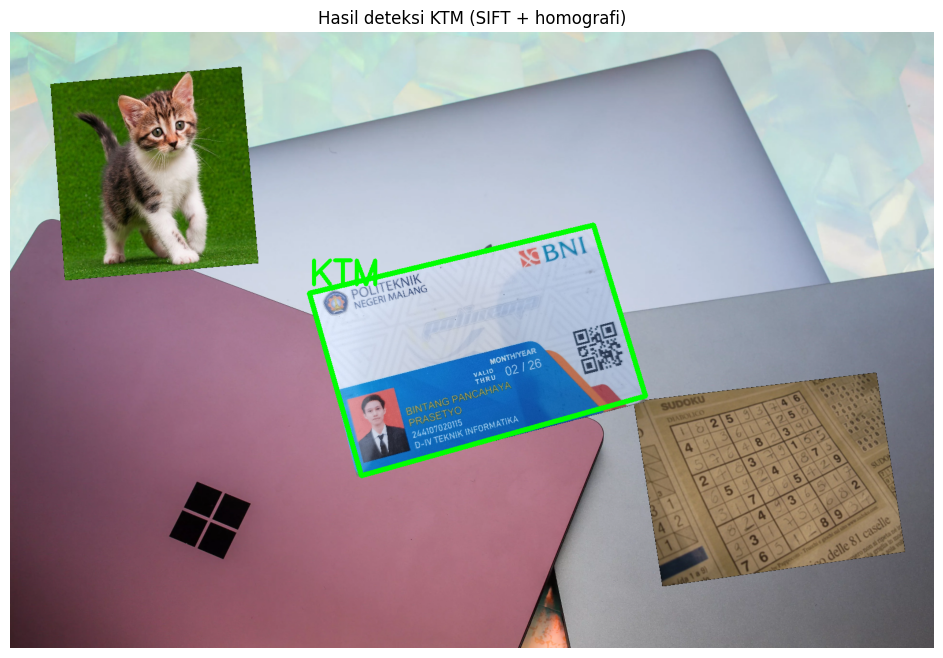

In [ ]:
# 3. Lokalisasi KTM pada citra dengan homografi dari good matches SIFT
src_pts = np.float32([kp1[m[0].queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst_pts = np.float32([kp2[m[0].trainIdx].pt for m in good]).reshape(-1, 1, 2)
H, inlier = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
print('Jumlah inlier RANSAC :', int(inlier.sum()), 'dari', len(good))

h, w = ktm_ref.shape
sudut = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
lokasi = cv.perspectiveTransform(sudut, H)

hasil = scene_rgb.copy()
cv.polylines(hasil, [np.int32(lokasi)], True, (0, 255, 0), 8)
cv.putText(hasil, 'KTM', tuple(np.int32(lokasi[0, 0]) + np.array([0, -15])), cv.FONT_HERSHEY_SIMPLEX, 2, (0, 255, 0), 5)

plt.figure(figsize=(12, 8))
plt.imshow(hasil), plt.title('Hasil deteksi KTM (SIFT + homografi)'), plt.axis('off')
plt.show()

**Analisis:** ORB menghasilkan banyak match, tetapi 25 match terbaiknya masih bercampur dengan pasangan titik yang salah. SIFT + ratio test menghasilkan *good match* yang jauh lebih konsisten (hampir semua garis menuju KTM pada citra uji), sehingga homografi dengan RANSAC dapat menentukan lokasi KTM dengan tepat walaupun KTM pada citra uji difoto ulang, ukurannya berbeda, miring, dan terletak bersama barang lain.

## D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN
### Persiapan data training dan testing
Data yang dibutuhkan adalah citra angka 0–9. Pada modul, angka dipotong satu per satu dengan image editor. Di sini pemotongan dilakukan otomatis dengan kode:
1. Area foto KTM (latar merah) dicari dengan segmentasi warna HSV, lalu area teks di sebelah kanan foto diambil.
2. Teks terang dipisahkan dari latar biru dengan *white top-hat* + threshold Otsu, lalu tiap huruf/angka dipisahkan dengan *connected components*.
3. Komponen dikelompokkan per baris; baris **NIM** adalah baris yang berisi 12 karakter.

Pembagian data:
- **Training** → digit NIM dari 3 foto KTM (`KTM1a`, `KTM1b`/`ktm.jpg`, `KTM1c`) + augmentasi. Karena NIM hanya berisi angka 0, 1, 2, 4, 5, 7, angka yang belum ada (3, 6, 8, 9) dilengkapi dengan citra angka yang dibuat dari beberapa font, sehingga tersedia data untuk semua kelas 0–9.
- **Testing** → NIM pada foto KTM lain (`ktm2.jpg` / `KTM1d`) yang tidak dipakai saat training.

Jumlah digit terpotong : 12


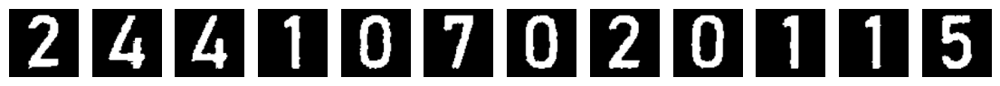

In [ ]:
NIM = '244107020115'      # label NIM pada KTM (untuk data training)
SIZE = 100

def area_foto(img):
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    m = cv.inRange(hsv, (0, 90, 70), (10, 255, 255)) | cv.inRange(hsv, (170, 90, 70), (180, 255, 255))
    m[:, int(0.4 * img.shape[1]):] = 0                 # foto selalu berada di sisi kiri KTM
    m = cv.morphologyEx(m, cv.MORPH_CLOSE, np.ones((25, 25), np.uint8))
    cs_, _ = cv.findContours(m, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    return cv.boundingRect(max(cs_, key=cv.contourArea))

def normalisasi(biner):
    # crop karakter -> tambah padding agar persegi -> resize 100x100 (karakter putih, latar hitam)
    ys, xs = np.where(biner > 0)
    c = biner[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    s = int(max(c.shape) * 1.3)
    kanvas = np.zeros((s, s), np.uint8)
    oy, ox = (s - c.shape[0]) // 2, (s - c.shape[1]) // 2
    kanvas[oy:oy + c.shape[0], ox:ox + c.shape[1]] = c
    return cv.resize(kanvas, (SIZE, SIZE), interpolation=cv.INTER_AREA)

def potong_digit_nim(img, n_digit=12):
    x, y, w, h = area_foto(img)
    x0, x1 = x + w, min(img.shape[1], x + int(4.5 * w))
    y0, y1 = y, min(img.shape[0], y + int(2.0 * h))
    gray = cv.cvtColor(img[y0:y1, x0:x1], cv.COLOR_BGR2GRAY)
    k = max(15, int(0.25 * h)) | 1
    tophat = cv.morphologyEx(gray, cv.MORPH_TOPHAT, cv.getStructuringElement(cv.MORPH_RECT, (k, k)))
    _, biner = cv.threshold(tophat, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    n, lab, st, cen = cv.connectedComponentsWithStats(biner)
    comps = [i for i in range(1, n) if st[i][4] > 30 and 0.12 * h < st[i][3] < 0.6 * h]
    # kelompokkan komponen per baris teks
    baris = []
    for i in sorted(comps, key=lambda i: cen[i][1]):
        for b in baris:
            if abs(np.mean([cen[j][1] for j in b]) - cen[i][1]) < 0.08 * h:
                b.append(i); break
        else:
            baris.append([i])
    nim = min(baris, key=lambda b: abs(len(b) - n_digit))     # baris NIM = baris dengan 12 karakter
    nim = sorted(nim, key=lambda i: st[i][0])                   # urut kiri -> kanan
    return [normalisasi((lab == i).astype(np.uint8) * 255) for i in nim]

# contoh hasil pemotongan digit NIM dari KTM testing
digit_test = potong_digit_nim(cv.imread(PATH + 'ktm2.jpg'))
print('Jumlah digit terpotong :', len(digit_test))
plt.figure(figsize=(14, 2))
for i, d in enumerate(digit_test):
    plt.subplot(1, len(digit_test), i + 1), plt.imshow(d, cmap='gray'), plt.axis('off')
plt.show()

In [ ]:
import shutil, glob, random
from PIL import Image, ImageDraw, ImageFont

random.seed(42); np.random.seed(42)
shutil.rmtree('dataset', ignore_errors=True)
for d in '0123456789':
    os.makedirs(f'dataset/training/{d}', exist_ok=True)

def augmentasi(img):
    # rotasi, skala, geser, tebal-tipis goresan, blur, dan noise acak
    M = cv.getRotationMatrix2D((SIZE / 2, SIZE / 2), random.uniform(-8, 8), random.uniform(0.85, 1.1))
    M[:, 2] += np.random.uniform(-6, 6, 2)
    out = cv.warpAffine(img, M, (SIZE, SIZE))
    r = random.random()
    if r < 0.25:
        out = cv.erode(out, np.ones((2, 2), np.uint8))
    elif r < 0.5:
        out = cv.dilate(out, np.ones((2, 2), np.uint8))
    if random.random() < 0.5:
        out = cv.GaussianBlur(out, (3, 3), 0)
    out = np.clip(out + np.random.normal(0, 8, out.shape), 0, 255).astype(np.uint8)
    return out

# 1. digit asli dari 3 foto KTM (training)
ktm_training = [PATH + 'ktm.jpg', '/content/drive/MyDrive/PCVK/KTM1a.jpg', '/content/drive/MyDrive/PCVK/KTM1c.jpg']
for p in ktm_training:
    digits = potong_digit_nim(cv.imread(p))
    print(os.path.basename(p), '->', len(digits), 'digit')
    for j, (lbl, d) in enumerate(zip(NIM, digits)):
        cv.imwrite(f'dataset/training/{lbl}/ktm_{os.path.basename(p)[:-4]}_{j}.png', d)
        for a in range(25):
            cv.imwrite(f'dataset/training/{lbl}/ktm_{os.path.basename(p)[:-4]}_{j}_aug{a}.png', augmentasi(d))

# 2. digit dari beberapa font (melengkapi angka 0-9)
font_files = [f for f in glob.glob('/usr/share/fonts/**/*.ttf', recursive=True)
              if re.search(r'(DejaVuSans|LiberationSans|LiberationMono)', os.path.basename(f))]
print('Jumlah font :', len(font_files))
for d in '0123456789':
    for fi, ff in enumerate(font_files):
        kanvas = Image.new('L', (200, 200), 0)
        ImageDraw.Draw(kanvas).text((40, 10), d, fill=255, font=ImageFont.truetype(ff, 150))
        base = normalisasi(np.array(kanvas))
        # variasi lebar huruf (condensed) agar mirip font KTM
        for sx in [1.0, 0.8, 0.65]:
            sempit = normalisasi(cv.resize(base, (int(SIZE * sx), SIZE)))
            for a in range(8):
                cv.imwrite(f'dataset/training/{d}/font{fi}_{sx}_{a}.png', augmentasi(sempit))

# 3. data testing: NIM dari KTM lain (ktm2.jpg)
os.makedirs('dataset/testing/ktm_bintang', exist_ok=True)
for j, d in enumerate(digit_test):
    cv.imwrite(f'dataset/testing/ktm_bintang/{j:02d}.png', d)

for d in '0123456789':
    print(d, len(os.listdir(f'dataset/training/{d}')), end=' | ')

ktm.jpg -> 12 digit
KTM1a.jpg -> 12 digit
KTM1c.jpg -> 12 digit
Jumlah font : 8
0 426 | 1 426 | 2 348 | 3 192 | 4 348 | 5 270 | 6 192 | 7 270 | 8 192 | 9 192 | 

### Persiapan training (source code modul)

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"   # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))   # daftar nama kelas
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img),
                                   cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

9: 100%|██████████| 192/192 [00:00<00:00, 2924.11it/s]


jumlah data : 2856
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


### Training data (source code modul)

In [ ]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]   # diambil dari data, tidak ditulis tetap

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 46s 603ms/step - accuracy: 0.6764 - loss: 1.0628 - val_accuracy: 0.9423 - val_loss: 0.2060
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 40s 558ms/step - accuracy: 0.9597 - loss: 0.1381 - val_accuracy: 0.9598 - val_loss: 0.1210
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 42s 586ms/step - accuracy: 0.9851 - loss: 0.0540 - val_accuracy: 0.9790 - val_loss: 0.0638
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 43s 594ms/step - accuracy: 0.9869 - loss: 0.0404 - val_accuracy: 0.9738 - val_loss: 0.0624
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 81s 577ms/step - accuracy: 0.9934 - loss: 0.0236 - val_accuracy: 0.9983 - val_loss: 0.0142
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 43s 596ms/step - accuracy: 0.9996 - loss: 0.0052 - val_accuracy: 0.9948 - val_loss: 0.0177
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 564ms/step - accuracy: 0.9996 - loss: 0.0023 - val_accuracy: 0.9965 - val_loss: 0.0112
Epoch 8/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 42s 569ms/step - accuracy: 0.9987 - loss: 0.0053 - val_accu

### Testing data (source code modul)

In [ ]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))   # urutan kelas saat training

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

folder name: ktm_bintang no: 244107020115


NIM sebenarnya  : 244107020115
Hasil pengenalan: 244107020115
Akurasi per karakter : 12/12 = 100%


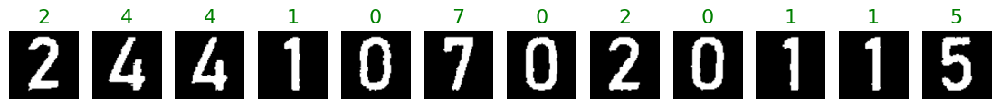

In [ ]:
# menampilkan karakter KTM beserta hasil pengenalan CNN
hasil_nim = temp
benar = sum(a == b for a, b in zip(hasil_nim, NIM))
print('NIM sebenarnya  :', NIM)
print('Hasil pengenalan:', hasil_nim)
print(f'Akurasi per karakter : {benar}/{len(NIM)} = {benar / len(NIM):.0%}')

plt.figure(figsize=(14, 2.5))
for i, (d, p) in enumerate(zip(digit_test, hasil_nim)):
    plt.subplot(1, len(digit_test), i + 1), plt.imshow(d, cmap='gray'), plt.axis('off')
    plt.title(p, color='green' if i < len(NIM) and p == NIM[i] else 'red', fontsize=16)
plt.show()

**Analisis:** Model CNN mencapai akurasi training 100% dan akurasi validasi ±99%. Pada data testing, yaitu NIM dari foto KTM yang tidak dipakai saat training (`ktm2.jpg`), seluruh 12 karakter NIM **244107020115** dikenali dengan benar. Pemotongan karakter otomatis (segmentasi warna untuk mencari foto, *top-hat* + Otsu, dan *connected components*) membuat tiap digit bersih dan berukuran seragam, sehingga CNN cukup mempelajari bentuk angka. Penambahan data angka dari beberapa font membuat model tetap punya contoh untuk angka 3, 6, 8, dan 9 yang tidak ada pada NIM.